<a href="https://colab.research.google.com/github/2503a51088/Lab_Assignment/blob/main/TECHNOLOGY_TRENDS_ANALYTICS.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

# ==========================================
# TECHNOLOGY TRENDS ANALYTICS
# Final Project - Data Analytics and Visualization
# ==========================================

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go

from IPython.display import display

# Visualization settings
sns.set_theme(style="whitegrid", palette="deep")

plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.labelsize"] = 11

print("All libraries imported successfully!")


All libraries imported successfully!


In [ ]:

# Upload the original dataset

from google.colab import files

uploaded = files.upload()

file_name = list(uploaded.keys())[0]

df = pd.read_csv(file_name)

print("Dataset loaded successfully!")
print("Dataset Name:", file_name)


Saving Technology_Trends_Dashboard_1000_Raw_Dataset(1).csv to Technology_Trends_Dashboard_1000_Raw_Dataset(1).csv
Dataset loaded successfully!
Dataset Name: Technology_Trends_Dashboard_1000_Raw_Dataset(1).csv


In [ ]:

# Initial Dataset Exploration

print("DATASET OVERVIEW")
print("=" * 45)

print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

print("\nCOLUMN NAMES")
print(df.columns.tolist())

print("\nFIRST FIVE RECORDS")
display(df.head())

print("\nDATA TYPES")
display(df.dtypes)

print("\nMISSING VALUES")
display(df.isnull().sum())

print("\nDUPLICATE RECORDS")
print(df.duplicated().sum())


DATASET OVERVIEW
Number of Rows: 1000
Number of Columns: 13

COLUMN NAMES
['record_id', 'year', 'month', 'technology', 'category', 'job_postings', 'mentions', 'popularity_score', 'demand_index', 'average_salary_usd', 'region', 'experience_level', 'source']

FIRST FIVE RECORDS


,record_id,year,month,technology,category,job_postings,mentions,popularity_score,demand_index,average_salary_usd,region,experience_level,source
0,1,2019,4,Power BI,Data Analytics,NaN,4963,80.25,66.25,112385.0,South America,Mid,Stack Overflow
1,2,2025,6,Angular,Web Development,2318,6431,77.28,68.84,123930.0,Europe,Mid,GitHub
2,3,2025,8,Apache Spark,Big Data,854,5151,69.00,58.1,117877.0,North America,Mid,Job Portal
3,4,2026,6,Jenkins,DevOps,644,2226,69.94,74.91,141080.0,Asia,Lead,Job Portal
4,5,2020,9,Rust,Programming Language,726,2481,45.28,37.86,69657.0,Europe,Junior,GitHub



DATA TYPES


,0
record_id,int64
year,int64
month,int64
technology,object
category,object
job_postings,object
mentions,int64
popularity_score,float64
demand_index,object
average_salary_usd,float64



MISSING VALUES


,0
record_id,0
year,0
month,0
technology,19
category,12
job_postings,18
mentions,0
popularity_score,19
demand_index,0
average_salary_usd,16



DUPLICATE RECORDS
20


In [ ]:

# Missing Value Analysis

missing_values = df.isnull().sum()

missing_report = pd.DataFrame({
    "Missing Values": missing_values,
    "Missing Percentage": (missing_values / len(df)) * 100
})

missing_report = missing_report[
    missing_report["Missing Values"] > 0
].sort_values(by="Missing Values", ascending=False)

print("MISSING VALUE REPORT")
display(missing_report.round(2))


MISSING VALUE REPORT


,Missing Values,Missing Percentage
region,21,2.1
popularity_score,19,1.9
technology,19,1.9
job_postings,18,1.8
average_salary_usd,16,1.6
category,12,1.2
source,3,0.3


In [ ]:

# Duplicate Record Analysis

duplicate_count = df.duplicated().sum()

print("Total Records:", len(df))
print("Duplicate Records:", duplicate_count)
print("Unique Records:", len(df) - duplicate_count)

print("\nDuplicate Record Samples:")
display(df[df.duplicated(keep=False)].head(10))


Total Records: 1000
Duplicate Records: 20
Unique Records: 980

Duplicate Record Samples:


,record_id,year,month,technology,category,job_postings,mentions,popularity_score,demand_index,average_salary_usd,region,experience_level,source
100,101,2024,2,Google Cloud,Cloud,908,5768,79.73,78.97,125119.0,India,Entry,Company Hiring Data
101,102,2019,10,SQL,Database,2501,7816,98.14,100,118906.0,Europe,Entry,GitHub
102,103,2022,10,Google Cloud,Cloud,2352,3971,88.88,95.49,127965.0,South America,Entry,Job Portal
103,104,2019,12,Kubernetes,DevOps,1920,5189,82.06,81.36,92070.0,North America,Entry,Developer Survey
104,105,2020,10,C#,Programming Language,2062,2955,150.00,58.12,64332.0,Asia,Entry,Company Hiring Data
105,106,2020,1,TypeScript,Programming Language,1355,4811,86.13,89.04,114382.0,India,Senior,Developer Survey
106,107,2022,10,postgresql,Database,1578,6378,86.86,94.83,130781.0,Australia,Entry,Stack Overflow
107,108,2024,3,Java,Programming Language,1895,5577,95.42,93.21,107061.0,Europe,Mid,Stack Overflow
108,109,2023,11,GitHub,Developer Tools,2110,4859,87.26,71.76,125550.0,Asia,Junior,GitHub
109,110,2019,1,Microsoft Azure,Cloud,1502,5612,88.00,87.44,102176.0,South America,Mid,Developer Survey


In [ ]:
for column in df.columns:
    print("\n" + "="*50)
    print(column)
    print("Unique values:", df[column].nunique())

    if df[column].dtype == "object":
        print(df[column].dropna().unique()[:20])


record_id
Unique values: 980

year
Unique values: 11

month
Unique values: 12

technology
Unique values: 68
['Power BI' 'Angular' 'Apache Spark' 'Jenkins' 'Rust' 'Redis'
 'Hugging Face' 'MySQL' 'Python' 'C#' 'Pandas' 'AWS' 'React' 'PyTorch'
 'PostgreSQL' 'scikit-learn ' 'OpenAI' 'TensorFlow' 'Microsoft Azure' 'Go']

category
Unique values: 10
['Data Analytics' 'Web Development' 'Big Data' 'DevOps'
 'Programming Language' 'Database' 'Generative AI' 'Cloud' 'AI/ML'
 'Developer Tools']

job_postings
Unique values: 775
['2318' '854' '644' '726' '1254' '1009' '553' '691' '2529' '1889' '1147'
 '802' '2167' '1475' '2036' '1675' '3478' '1801' '2906' '2915']

mentions
Unique values: 895

popularity_score
Unique values: 753

demand_index
Unique values: 800
['66.25' '68.84' '58.1' '74.91' '37.86' '50.88' '49.37' '59.55' '74.57'
 '82.54' '88.85' '100' '61.69' '93.27' '75.82' '88.07' '85.1' '94.36'
 '78.9' '79.91']

average_salary_usd
Unique values: 932

region
Unique values: 18
['South America' '

In [ ]:
# DATA CLEANING AND PREPARATION

# Create a separate cleaned dataset
df_clean = df.copy()

# 1. Remove exact duplicate records
before = len(df_clean)
df_clean = df_clean.drop_duplicates().copy()
print("Duplicate records removed:", before - len(df_clean))

# 2. Convert numerical columns to appropriate data types
numeric_columns = [
    "year", "month", "job_postings", "mentions",
    "popularity_score", "demand_index", "average_salary_usd"
]

for column in numeric_columns:
    df_clean[column] = pd.to_numeric(
        df_clean[column], errors="coerce"
    )

# 3. Remove extra spaces from text columns
text_columns = [
    "technology", "category", "region",
    "experience_level", "source"
]

for column in text_columns:
    df_clean[column] = (
        df_clean[column].astype("string").str.strip()
    )

# 4. Standardize region names
region_mapping = {
    "india": "India",
    "india ": "India",
    "northamerica": "North America",
    "n. america": "North America",
    "north america": "North America",
    "european": "Europe",
    "eu": "Europe",
    "europe": "Europe",
    "asian": "Asia",
    "asia": "Asia",
    "south america": "South America",
    "australia": "Australia"
}

df_clean["region"] = (
    df_clean["region"].str.lower().replace(region_mapping)
)

# 5. Handle invalid year and month values
df_clean.loc[
    ~df_clean["year"].between(2018, 2026),
    "year"
] = np.nan

# Check for invalid month values
invalid_months = ~df_clean["month"].between(1, 12)

print("Invalid month records:", invalid_months.sum())
# 6. Handle invalid numerical values
for column in ["popularity_score", "demand_index"]:
    df_clean.loc[
        ~df_clean[column].between(0, 100),
        column
    ] = np.nan

df_clean.loc[
    df_clean["average_salary_usd"] <= 0,
    "average_salary_usd"
] = np.nan

df_clean.loc[
    df_clean["job_postings"] < 0,
    "job_postings"
] = np.nan

# Use the cleaned dataset for the remaining analysis
df = df_clean.copy()

print("\nDATA CLEANING COMPLETED")
print("Original Records:", len(df_clean) + (before - len(df_clean)))
print("Cleaned Records:", len(df))
print("Cleaned Dataset Shape:", df.shape)

Duplicate records removed: 20
Invalid month records: 0

DATA CLEANING COMPLETED
Original Records: 1000
Cleaned Records: 980
Cleaned Dataset Shape: (980, 13)


In [ ]:
# CLEANED DATASET VERIFICATION

print("CLEANED DATASET SUMMARY")
print("=" * 45)

print("Total Records:", len(df))
print("Total Columns:", df.shape[1])

print("\nREMAINING MISSING VALUES")
display(df.isnull().sum())

print("\nDUPLICATE RECORDS")
print(df.duplicated().sum())

print("\nUPDATED DATA TYPES")
display(df.dtypes)

print("\nSTATISTICAL SUMMARY")
display(df.describe().round(2))

CLEANED DATASET SUMMARY
Total Records: 980
Total Columns: 13

REMAINING MISSING VALUES


,0
record_id,0
year,5
month,0
technology,19
category,12
job_postings,25
mentions,0
popularity_score,24
demand_index,6
average_salary_usd,21



DUPLICATE RECORDS
0

UPDATED DATA TYPES


,0
record_id,int64
year,float64
month,int64
technology,string[python]
category,string[python]
job_postings,float64
mentions,int64
popularity_score,float64
demand_index,float64
average_salary_usd,float64



STATISTICAL SUMMARY


,record_id,year,month,job_postings,mentions,popularity_score,demand_index,average_salary_usd
count,980.00,975.00,980.00,955.00,980.00,956.00,974.00,959.00
mean,490.50,2021.95,6.88,1689.56,5021.32,79.36,76.67,110501.68
std,283.05,2.01,3.38,699.40,1787.16,15.35,15.71,19773.35
min,1.00,2018.00,1.00,354.00,1338.00,29.35,31.24,48914.00
25%,245.75,2020.00,4.00,1090.50,3625.25,67.43,64.28,97496.50
50%,490.50,2022.00,7.00,1628.00,4910.00,81.14,78.41,110598.00
75%,735.25,2024.00,10.00,2222.00,6265.50,92.02,89.10,123762.00
max,980.00,2026.00,12.00,3478.00,9457.00,100.00,100.00,180000.00


In [ ]:
df.head()

,record_id,year,month,technology,category,job_postings,mentions,popularity_score,demand_index,average_salary_usd,region,experience_level,source
0,1,2019.0,4,Power BI,Data Analytics,NaN,4963,80.25,66.25,112385.0,South America,Mid,Stack Overflow
1,2,2025.0,6,Angular,Web Development,2318.0,6431,77.28,68.84,123930.0,Europe,Mid,GitHub
2,3,2025.0,8,Apache Spark,Big Data,854.0,5151,69.00,58.10,117877.0,North America,Mid,Job Portal
3,4,2026.0,6,Jenkins,DevOps,644.0,2226,69.94,74.91,141080.0,Asia,Lead,Job Portal
4,5,2020.0,9,Rust,Programming Language,726.0,2481,45.28,37.86,69657.0,Europe,Junior,GitHub


In [ ]:
# 1. TECHNOLOGY POPULARITY ANALYSIS

popularity_data = (
    df.dropna(subset=["technology", "popularity_score"])
    .groupby("technology", as_index=False)
    ["popularity_score"].mean()
    .nlargest(10, "popularity_score")
)

fig = px.bar(
    popularity_data,
    x="popularity_score",
    y="technology",
    orientation="h",
    color="popularity_score",
    text_auto=".2f",
    title="Top 10 Technologies by Average Popularity",
    labels={
        "technology": "Technology",
        "popularity_score": "Average Popularity Score"
    },
    color_continuous_scale="Blues"
)

fig.update_layout(
    template="plotly_white",
    title_x=0.5,
    height=550,
    yaxis=dict(categoryorder="total ascending")
)

fig.show()

In [ ]:
# 2. TECHNOLOGY DEMAND BY CATEGORY

category_data = (
    df.dropna(subset=["category", "job_postings"])
    .groupby("category", as_index=False)["job_postings"]
    .sum()
    .sort_values("job_postings", ascending=False)
)

fig = px.treemap(
    category_data,
    path=["category"],
    values="job_postings",
    color="job_postings",
    color_continuous_scale="Blues",
    title="Technology Demand Across Categories"
)

fig.update_layout(
    template="plotly_white",
    title_x=0.5,
    height=600
)

fig.show()

In [ ]:
# 3. SALARY DISTRIBUTION BY EXPERIENCE LEVEL

salary_data = df.dropna(
    subset=["experience_level", "average_salary_usd"]
)

fig = px.box(
    salary_data,
    x="experience_level",
    y="average_salary_usd",
    color="experience_level",
    title="Salary Distribution Across Experience Levels",
    labels={
        "experience_level": "Experience Level",
        "average_salary_usd": "Average Salary (USD)"
    },
    points="outliers"
)

fig.update_layout(
    template="plotly_white",
    title_x=0.5,
    height=550,
    showlegend=False
)

fig.show()

In [ ]:
# 4. TECHNOLOGY TRENDS OVER THE YEARS

trend_data = (
    df.dropna(subset=["year", "category", "popularity_score"])
    .groupby(["year", "category"], as_index=False)
    ["popularity_score"].mean()
)

fig = px.line(
    trend_data,
    x="year",
    y="popularity_score",
    color="category",
    markers=True,
    title="Technology Popularity Trends Across Years",
    labels={
        "year": "Year",
        "popularity_score": "Average Popularity Score",
        "category": "Technology Category"
    }
)

fig.update_layout(
    template="plotly_white",
    title_x=0.5,
    height=600,
    hovermode="x unified"
)

fig.show()

In [ ]:
# HISTOGRAM PLOT - SALARY DISTRIBUTION
hist_data = df.dropna(subset=["average_salary_usd", "experience_level"]).copy()
hist_data["experience_level"] = hist_data["experience_level"].astype(str)

fig = px.histogram(
    hist_data,
    x="average_salary_usd",
    nbins=30,
    marginal="box",
    opacity=0.85,
    color_discrete_sequence=["#2b5c8f"],
    title="Distribution of Average Technology Salaries (USD)",
    labels={
        "average_salary_usd": "Average Salary (USD)",
        "count": "Frequency"
    }
)

fig.update_layout(
    template="plotly_white",
    title_x=0.5,
    height=550,
    xaxis_title="Average Salary (USD)",
    yaxis_title="Number of Records",
    bargap=0.05
)

fig.show()

In [ ]:
# 5. REGIONAL TECHNOLOGY DEMAND ANALYSIS

regional_data = (
    df.dropna(subset=["region", "category", "job_postings"])
    .groupby(["region", "category"], as_index=False)
    ["job_postings"].sum()
)

fig = px.bar(
    regional_data,
    x="region",
    y="job_postings",
    color="category",
    barmode="group",
    title="Technology Demand Across Different Regions",
    labels={
        "region": "Region",
        "job_postings": "Total Job Postings",
        "category": "Technology Category"
    }
)

fig.update_layout(
    template="plotly_white",
    title_x=0.5,
    height=600,
    xaxis_tickangle=-30,
    legend_title="Technology Category"
)

fig.show()

In [ ]:
# 3D SCATTER PLOT - TECHNOLOGY TRENDS ANALYSIS
scatter_3d_data = df.copy()

# Convert required columns to numeric
numeric_columns = [
    "popularity_score",
    "demand_index",
    "average_salary_usd",
    "mentions",
    "year",
    "job_postings"
]
for col in numeric_columns:
    scatter_3d_data[col] = pd.to_numeric(
        scatter_3d_data[col], errors="coerce"
    )

# Remove rows with missing values in chart fields
scatter_3d_data = scatter_3d_data.dropna(
    subset=[
        "technology",
        "category",
        "popularity_score",
        "demand_index",
        "average_salary_usd",
        "mentions"
    ]
).copy()

# Ensure bubble sizes are positive
scatter_3d_data = scatter_3d_data[
    scatter_3d_data["mentions"] > 0
].copy()

# Convert nullable string columns to standard strings to avoid NAType JSON serialization error
for col in ["technology", "category", "region"]:
    scatter_3d_data[col] = scatter_3d_data[col].fillna("Unknown").astype(str)

# Create 3D scatter plot
fig = px.scatter_3d(
    scatter_3d_data,
    x="popularity_score",
    y="demand_index",
    z="average_salary_usd",
    color="category",
    size="mentions",
    size_max=15,
    opacity=0.8,
    hover_name="technology",
    hover_data=["year", "job_postings", "region"],
    title="3D Analysis of Technology Popularity, Demand and Salary",
    labels={
        "popularity_score": "Popularity Score",
        "demand_index": "Demand Index",
        "average_salary_usd": "Average Salary (USD)",
        "category": "Technology Category",
        "mentions": "Technology Mentions"
    }
)

fig.update_layout(
    template="plotly_white",
    title_x=0.5,
    height=700,
    scene=dict(
        xaxis_title="Popularity Score",
        yaxis_title="Demand Index",
        zaxis_title="Average Salary (USD)"
    ),
    legend_title="Technology Category"
)

fig.show()

In [ ]:
# 3D GLOBE MAP PLOT - REGIONAL TECHNOLOGY TRENDS
map_data = (
    df.dropna(subset=["region", "job_postings", "popularity_score", "average_salary_usd"])
    .groupby("region", as_index=False)
    .agg(
        Total_Job_Postings=("job_postings", "sum"),
        Total_Mentions=("mentions", "sum"),
        Avg_Popularity=("popularity_score", "mean"),
        Avg_Salary=("average_salary_usd", "mean")
    )
)

# Map regions to representative coordinates (Latitude, Longitude)
region_coords = {
    "North America": (39.8283, -98.5795),
    "South America": (-14.2350, -51.9253),
    "Europe": (50.1109, 8.6821),
    "Asia": (34.0479, 100.6197),
    "India": (20.5937, 78.9629),
    "Australia": (-25.2744, 133.7751)
}

map_data["lat"] = map_data["region"].map(lambda r: region_coords.get(r, (None, None))[0])
map_data["lon"] = map_data["region"].map(lambda r: region_coords.get(r, (None, None))[1])
map_data = map_data.dropna(subset=["lat", "lon"]).copy()

# Convert region column to standard string to avoid JSON serialization issues
map_data["region"] = map_data["region"].astype(str)

# Create 3D Orthographic Globe Plot
fig = px.scatter_geo(
    map_data,
    lat="lat",
    lon="lon",
    size="Total_Job_Postings",
    color="Avg_Salary",
    hover_name="region",
    hover_data={
        "lat": False,
        "lon": False,
        "Total_Job_Postings": ":,.0f",
        "Total_Mentions": ":,.0f",
        "Avg_Popularity": ":.2f",
        "Avg_Salary": ":$,.2f"
    },
    size_max=45,
    color_continuous_scale="Viridis",
    projection="orthographic",
    title="3D Global Distribution of Tech Job Postings & Average Salary",
    labels={
        "Total_Job_Postings": "Total Job Postings",
        "Avg_Salary": "Avg Salary (USD)",
        "Avg_Popularity": "Avg Popularity Score",
        "Total_Mentions": "Total Mentions"
    }
)

fig.update_geos(
    showcountries=True,
    countrycolor="LightGray",
    showcoastlines=True,
    coastlinecolor="Gray",
    showland=True,
    landcolor="whitesmoke",
    showocean=True,
    oceancolor="aliceblue"
)

fig.update_layout(
    title_x=0.5,
    height=650
)

fig.show()

In [ ]:
# 6. TECHNOLOGY POPULARITY VS MARKET DEMAND

scatter_data = df.dropna(
    subset=["technology", "category", "popularity_score", "demand_index"]
)

fig = px.scatter(
    scatter_data,
    x="popularity_score",
    y="demand_index",
    color="category",
    hover_name="technology",
    size="mentions",
    size_max=7,
    opacity=0.75,
    title="Technology Popularity vs Market Demand",
    labels={
        "popularity_score": "Popularity Score",
        "demand_index": "Demand Index",
        "category": "Technology Category",
        "mentions": "Technology Mentions"
    }
)

fig.update_layout(
    template="plotly_white",
    title_x=0.5,
    height=600
)

fig.show()

## 4. Descriptive Statistical Analysis

Descriptive statistics are used to summarize the main characteristics of the dataset. Measures such as mean, median, standard deviation, minimum and maximum help us understand technology trends and market demand.

In [ ]:
# DESCRIPTIVE STATISTICAL ANALYSIS

numeric_columns = [
    "job_postings",
    "mentions",
    "popularity_score",
    "demand_index",
    "average_salary_usd"
]

print("DESCRIPTIVE STATISTICS")
print("=" * 60)

display(df[numeric_columns].describe().round(2))

# Calculate additional statistical measures
statistics = pd.DataFrame({
    "Mean": df[numeric_columns].mean(),
    "Median": df[numeric_columns].median(),
    "Mode": df[numeric_columns].mode().iloc[0],
    "Standard Deviation": df[numeric_columns].std(),
    "Variance": df[numeric_columns].var(),
    "Skewness": df[numeric_columns].skew()
})

print("\nADDITIONAL STATISTICAL MEASURES")
display(statistics.round(2))

DESCRIPTIVE STATISTICS


,job_postings,mentions,popularity_score,demand_index,average_salary_usd
count,955.00,980.00,956.00,974.00,959.00
mean,1689.56,5021.32,79.36,76.67,110501.68
std,699.40,1787.16,15.35,15.71,19773.35
min,354.00,1338.00,29.35,31.24,48914.00
25%,1090.50,3625.25,67.43,64.28,97496.50
50%,1628.00,4910.00,81.14,78.41,110598.00
75%,2222.00,6265.50,92.02,89.10,123762.00
max,3478.00,9457.00,100.00,100.00,180000.00



ADDITIONAL STATISTICAL MEASURES


,Mean,Median,Mode,Standard Deviation,Variance,Skewness
job_postings,1689.56,1628.00,717.0,699.40,4.891576e+05,0.34
mentions,5021.32,4910.00,2870.0,1787.16,3.193947e+06,0.25
popularity_score,79.36,81.14,100.0,15.35,2.355800e+02,-0.42
demand_index,76.67,78.41,100.0,15.71,2.467300e+02,-0.28
average_salary_usd,110501.68,110598.00,123676.0,19773.35,3.909852e+08,0.02


## 5. Correlation Analysis

Correlation analysis is used to identify the strength and direction of relationships between numerical variables. A correlation matrix and heatmap help visualize these relationships.

CORRELATION MATRIX


,job_postings,mentions,popularity_score,demand_index,average_salary_usd
job_postings,1.00,0.24,0.44,0.40,0.17
mentions,0.24,1.00,0.54,0.49,0.19
popularity_score,0.44,0.54,1.00,0.91,0.40
demand_index,0.40,0.49,0.91,1.00,0.37
average_salary_usd,0.17,0.19,0.40,0.37,1.00


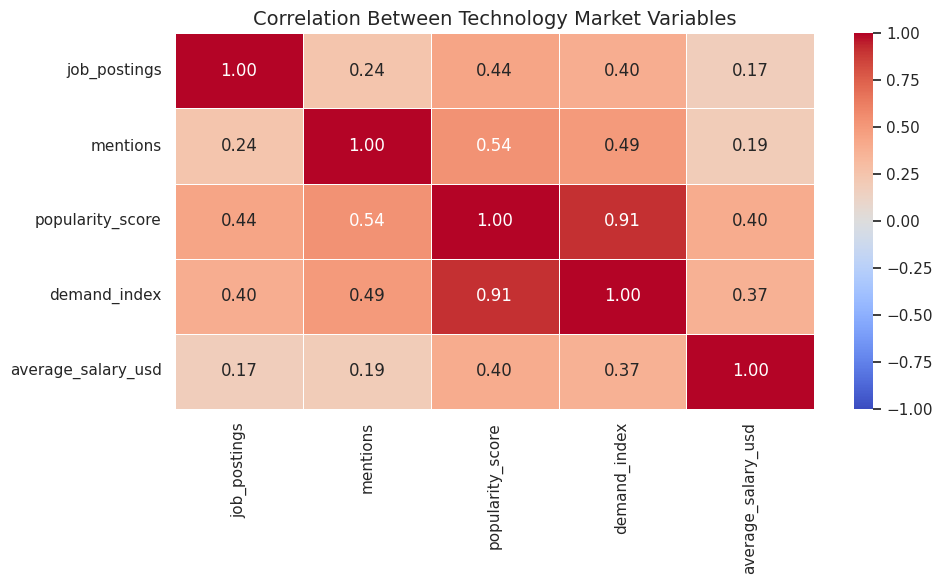

In [ ]:
# CORRELATION ANALYSIS

correlation_columns = [
    "job_postings",
    "mentions",
    "popularity_score",
    "demand_index",
    "average_salary_usd"
]

correlation_matrix = df[correlation_columns].corr()

print("CORRELATION MATRIX")
display(correlation_matrix.round(2))

# Correlation Heatmap

plt.figure(figsize=(10, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    vmin=-1,
    vmax=1
)

plt.title("Correlation Between Technology Market Variables")
plt.tight_layout()
plt.show()

## 6. Technology Growth Analysis

This analysis compares the popularity of technologies across different years to identify emerging and declining technologies.

In [ ]:
# TECHNOLOGY GROWTH ANALYSIS

growth_data = (
    df.dropna(subset=["technology", "year", "popularity_score"])
    .groupby(["technology", "year"], as_index=False)
    ["popularity_score"].mean()
)

# Calculate change between earliest and latest available year
growth_summary = (
    growth_data.sort_values("year")
    .groupby("technology")
    .agg(
        First_Year=("year", "min"),
        Last_Year=("year", "max"),
        Initial_Popularity=("popularity_score", "first"),
        Latest_Popularity=("popularity_score", "last"),
        Year_Count=("year", "nunique")
    )
    .reset_index()
)

growth_summary["Popularity_Change"] = (
    growth_summary["Latest_Popularity"]
    - growth_summary["Initial_Popularity"]
)

# Keep technologies with at least two observed years
growth_summary = growth_summary[
    growth_summary["Year_Count"] >= 2
].sort_values("Popularity_Change", ascending=False)

print("TECHNOLOGY POPULARITY GROWTH")
display(growth_summary.round(2))

# Top 10 technologies by popularity change
top_growth = growth_summary.head(10)

fig = px.bar(
    top_growth,
    x="Popularity_Change",
    y="technology",
    orientation="h",
    color="Popularity_Change",
    text_auto=".2f",
    title="Top 10 Technologies by Popularity Change",
    labels={
        "technology": "Technology",
        "Popularity_Change": "Change in Popularity Score"
    },
    color_continuous_scale="Teal"
)

fig.update_layout(
    template="plotly_white",
    title_x=0.5,
    height=550,
    yaxis={"categoryorder": "total ascending"}
)

fig.show()

TECHNOLOGY POPULARITY GROWTH


,technology,First_Year,Last_Year,Initial_Popularity,Latest_Popularity,Year_Count,Popularity_Change
39,PowerBI,2019.0,2023.0,71.80,100.00,2,28.20
16,Hugging Face,2019.0,2025.0,70.06,95.29,6,25.23
38,Power BI,2019.0,2025.0,78.21,99.90,7,21.69
54,apache spark,2021.0,2025.0,62.01,81.29,2,19.28
49,Tableau,2018.0,2025.0,69.30,88.44,8,19.14
28,MySQL,2019.0,2025.0,82.90,100.00,5,17.10
63,postgresql,2021.0,2023.0,83.17,99.86,3,16.69
6,C++,2019.0,2025.0,61.30,77.72,7,16.42
26,MongoDB,2019.0,2025.0,75.18,91.26,4,16.08
10,GITHUB,2019.0,2025.0,83.96,100.00,3,16.04


## 7. Business Insights and Recommendations

This section summarizes important findings from the technology trends dataset and provides data-driven recommendations for businesses.

In [ ]:
# BUSINESS INSIGHTS AND RECOMMENDATIONS

print("=" * 65)
print("       TECHNOLOGY TRENDS - BUSINESS INSIGHTS")
print("=" * 65)

# 1. Most popular technology
technology_popularity = (
    df.dropna(subset=["technology", "popularity_score"])
    .groupby("technology")["popularity_score"]
    .mean()
)

if not technology_popularity.empty:
    top_technology = technology_popularity.idxmax()
    top_score = technology_popularity.max()

    print("\n1. MOST POPULAR TECHNOLOGY")
    print(f"{top_technology}: Average popularity score = {top_score:.2f}")

# 2. Highest-demand category
category_demand = (
    df.dropna(subset=["category", "job_postings"])
    .groupby("category")["job_postings"]
    .sum()
)

if not category_demand.empty:
    top_category = category_demand.idxmax()
    top_postings = category_demand.max()

    print("\n2. HIGHEST-DEMAND CATEGORY")
    print(f"{top_category}: Total job postings = {top_postings:.0f}")

# 3. Region with highest job postings
regional_demand = (
    df.dropna(subset=["region", "job_postings"])
    .groupby("region")["job_postings"]
    .sum()
)

if not regional_demand.empty:
    top_region = regional_demand.idxmax()
    region_postings = regional_demand.max()

    print("\n3. LEADING REGION")
    print(f"{top_region}: Total job postings = {region_postings:.0f}")

# 4. Experience level with highest average salary
salary_by_experience = (
    df.dropna(subset=["experience_level", "average_salary_usd"])
    .groupby("experience_level")["average_salary_usd"]
    .mean()
)

if not salary_by_experience.empty:
    highest_salary_level = salary_by_experience.idxmax()
    highest_salary = salary_by_experience.max()

    print("\n4. HIGHEST-PAYING EXPERIENCE LEVEL")
    print(
        f"{highest_salary_level}: "
        f"Average salary = ${highest_salary:,.2f}"
    )

# 5. Technology with highest demand index
technology_demand = (
    df.dropna(subset=["technology", "demand_index"])
    .groupby("technology")["demand_index"]
    .mean()
)

if not technology_demand.empty:
    highest_demand_technology = technology_demand.idxmax()
    highest_demand_score = technology_demand.max()

    print("\n5. HIGHEST TECHNOLOGY DEMAND INDEX")
    print(
        f"{highest_demand_technology}: "
        f"Average demand index = {highest_demand_score:.2f}"
    )

print("\n" + "=" * 65)
print("             BUSINESS RECOMMENDATIONS")
print("=" * 65)

print("""
1. Businesses should monitor popular technologies to understand
   changing industry interests.

2. Organizations can use job posting trends to identify technology
   categories with greater hiring activity.

3. Companies can compare regional demand when planning recruitment
   and workforce development.

4. Training institutions can use salary and experience-level analysis
   to design relevant skill development programs.

5. Businesses should regularly analyze technology demand and popularity
   to support future workforce planning.
""")

       TECHNOLOGY TRENDS - BUSINESS INSIGHTS

1. MOST POPULAR TECHNOLOGY
Java Script: Average popularity score = 100.00

2. HIGHEST-DEMAND CATEGORY
Programming Language: Total job postings = 348635

3. LEADING REGION
South America: Total job postings = 309629

4. HIGHEST-PAYING EXPERIENCE LEVEL
Junior: Average salary = $111,365.29

5. HIGHEST TECHNOLOGY DEMAND INDEX
openai api: Average demand index = 100.00

             BUSINESS RECOMMENDATIONS

1. Businesses should monitor popular technologies to understand
   changing industry interests.

2. Organizations can use job posting trends to identify technology
   categories with greater hiring activity.

3. Companies can compare regional demand when planning recruitment
   and workforce development.

4. Training institutions can use salary and experience-level analysis
   to design relevant skill development programs.

5. Businesses should regularly analyze technology demand and popularity
   to support future workforce planning.



In [ ]:
# FINAL DATASET VALIDATION

print("=" * 55)
print("       FINAL DATASET VALIDATION REPORT")
print("=" * 55)

print("\n1. DATASET INFORMATION")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

print("\n2. DUPLICATE CHECK")
print("Duplicate records:", df.duplicated().sum())

print("\n3. MISSING VALUE CHECK")
display(df.isnull().sum())

print("\n4. DATA TYPE CHECK")
display(df.dtypes)

print("\n5. NUMERICAL VALUE VALIDATION")

print("Invalid months:",
      (~df["month"].between(1, 12)).sum())

print("Invalid popularity scores:",
      (~df["popularity_score"].dropna().between(0, 100)).sum())

print("Invalid demand scores:",
      (~df["demand_index"].dropna().between(0, 100)).sum())

print("\n6. TECHNOLOGY SUMMARY")
print("Unique technologies:", df["technology"].nunique())

print("\n7. YEAR COVERAGE")
print("Available years:", sorted(df["year"].dropna().unique()))

print("\n" + "=" * 55)
print("       VALIDATION REPORT COMPLETED")
print("=" * 55)

       FINAL DATASET VALIDATION REPORT

1. DATASET INFORMATION
Rows: 980
Columns: 13

2. DUPLICATE CHECK
Duplicate records: 0

3. MISSING VALUE CHECK


,0
record_id,0
year,5
month,0
technology,19
category,12
job_postings,25
mentions,0
popularity_score,24
demand_index,6
average_salary_usd,21



4. DATA TYPE CHECK


,0
record_id,int64
year,float64
month,int64
technology,string[python]
category,string[python]
job_postings,float64
mentions,int64
popularity_score,float64
demand_index,float64
average_salary_usd,float64



5. NUMERICAL VALUE VALIDATION
Invalid months: 0
Invalid popularity scores: 0
Invalid demand scores: 0

6. TECHNOLOGY SUMMARY
Unique technologies: 67

7. YEAR COVERAGE
Available years: [np.float64(2018.0), np.float64(2019.0), np.float64(2020.0), np.float64(2021.0), np.float64(2022.0), np.float64(2023.0), np.float64(2024.0), np.float64(2025.0), np.float64(2026.0)]

       VALIDATION REPORT COMPLETED


## 8. Exporting Cleaned Data and Analysis Results

The cleaned dataset and analytical summary tables are exported for further visualization and dashboard development using Power BI.

In [ ]:
# EXPORT CLEANED DATA AND ANALYSIS SUMMARIES

# 1. Technology summary
technology_summary = (
    df.dropna(subset=["technology"])
    .groupby("technology", as_index=False)
    .agg(
        Total_Job_Postings=("job_postings", "sum"),
        Total_Mentions=("mentions", "sum"),
        Average_Popularity=("popularity_score", "mean"),
        Average_Demand=("demand_index", "mean"),
        Average_Salary=("average_salary_usd", "mean")
    )
)

# 2. Category summary
category_summary = (
    df.dropna(subset=["category"])
    .groupby("category", as_index=False)
    .agg(
        Total_Job_Postings=("job_postings", "sum"),
        Total_Mentions=("mentions", "sum"),
        Average_Popularity=("popularity_score", "mean"),
        Average_Demand=("demand_index", "mean")
    )
)

# 3. Yearly trends
yearly_summary = (
    df.dropna(subset=["year"])
    .groupby("year", as_index=False)
    .agg(
        Total_Job_Postings=("job_postings", "sum"),
        Total_Mentions=("mentions", "sum"),
        Average_Popularity=("popularity_score", "mean"),
        Average_Demand=("demand_index", "mean")
    )
)

# 4. Regional summary
regional_summary = (
    df.dropna(subset=["region"])
    .groupby("region", as_index=False)
    .agg(
        Total_Job_Postings=("job_postings", "sum"),
        Total_Mentions=("mentions", "sum"),
        Average_Popularity=("popularity_score", "mean")
    )
)

# 5. Experience-level salary summary
salary_summary = (
    df.dropna(subset=["experience_level", "average_salary_usd"])
    .groupby("experience_level", as_index=False)
    .agg(
        Average_Salary=("average_salary_usd", "mean"),
        Median_Salary=("average_salary_usd", "median"),
        Total_Records=("average_salary_usd", "count")
    )
)

# 6. Export everything into one Excel workbook
output_file = "Technology_Trends_Analysis_Results.xlsx"

with pd.ExcelWriter(output_file, engine="openpyxl") as writer:

    df.to_excel(writer, sheet_name="Cleaned_Data", index=False)

    technology_summary.to_excel(
        writer, sheet_name="Technology_Summary", index=False
    )

    category_summary.to_excel(
        writer, sheet_name="Category_Summary", index=False
    )

    yearly_summary.to_excel(
        writer, sheet_name="Yearly_Trends", index=False
    )

    regional_summary.to_excel(
        writer, sheet_name="Regional_Summary", index=False
    )

    salary_summary.to_excel(
        writer, sheet_name="Salary_Summary", index=False
    )

print("EXPORT COMPLETED SUCCESSFULLY!")
print("File:", output_file)
print("\nSheets created:")
print("1. Cleaned_Data")
print("2. Technology_Summary")
print("3. Category_Summary")
print("4. Yearly_Trends")
print("5. Regional_Summary")
print("6. Salary_Summary")

# Download the Excel workbook
from google.colab import files
files.download(output_file)

EXPORT COMPLETED SUCCESSFULLY!
File: Technology_Trends_Analysis_Results.xlsx

Sheets created:
1. Cleaned_Data
2. Technology_Summary
3. Category_Summary
4. Yearly_Trends
5. Regional_Summary
6. Salary_Summary


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>